# Project: Investigating Medical Appointment No-Shows

## Table of Contents
<ul>
<li><a href="#intro">Introduction</a></li>
<li><a href="#wrangling">Data Wrangling</a></li>
<li><a href="#eda">Exploratory Data Analysis</a></li>
<li><a href="#conclusions">Conclusions</a></li>
</ul>

<a id='intro'></a>
## Introduction

### Dataset Description 

>This dataset contains information about medical appointments in Brazil and whether patients showed up for their scheduled apointments. It includes over 100,000 records and provides details such as patient age, gender, medical condition and if they received a text reminder.
>Some of the key variables in the dataset include age, gender, and SMS reminders. The main outcome variable indicates whether a patient missed their appointment.
>The purpose of this analysis is to explore patterns in the data and identify factors that may be associated with patients not showing up for their appointments.


### Question(s) for Analysis
>1. What is the distribution of SMS reminders in the dataset?
>2. How does receiving an SMS reminder relate to appointment no-show rates?
>3. How do SMS reminders and patient age relate to apointment no-show rates?

In [11]:
# Use this cell to set up import statements for all of the packages that you
#   plan to use.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# While optional for current notebooks, if you are having trouble with visualizations,
#   remember to include a 'magic word' so that your visualizations are plotted
#   inline with the notebook. See this page for more:
#   http://ipython.readthedocs.io/en/stable/interactive/magics.html


In [2]:
df = pd.read_csv('Database_No_show_appointments/noshowappointments-kagglev2-may-2016.csv')
df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


In [4]:
df["No-show"] = df["No-show"].map({"No": 0, "Yes": 1})

In [5]:

def no_show_rate(column):
    return df.groupby(column)["No-show"].mean()

def distribution(column):
    return df[column].value_counts()


**Univariate Analysis (Single Variable):**

In [6]:
distribution("SMS_received")

0    75045
1    35482
Name: SMS_received, dtype: int64

>75,045 appointments did NOT receive an SMS. 35,482 appointments did receive an SMS. This shows a distribution, not outcomes or no-show rates.


**Bivariate Analysis (Two Variables):**

In [7]:
no_show_rate("SMS_received")

SMS_received
0    0.167033
1    0.275745
Name: No-show, dtype: float64

>Patients who received an SMS reminder had a higher no-show rate (27.6%) compared to patients who did not receive an SMS reminder (16.7). This examines the relationship between SMS reminders and appointment attendance.

**Multivariate Analysis (Multiple Variables):**

In [8]:
df["Age_group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 35, 55, 75, 115],
    labels=["0-18", "19-35", "36-55", "56-75", "75+"]
)

df. groupby(["Age_group", "SMS_received"])["No-show"].mean()

Age_group  SMS_received
0-18       0               0.187961
           1               0.313427
19-35      0               0.185085
           1               0.339959
36-55      0               0.162967
           1               0.265202
56-75      0               0.135413
           1               0.196022
75+        0               0.144609
           1               0.205683
Name: No-show, dtype: float64

>By grouping patients by both age group and SMS reminder status. we can see whether the relationship between SMS reminders and no-show behavior differs across age groups. This examines how SMS reminders and patient age jointly relate to appointment no-show rates.

<a id='wrangling'></a>
## Data Wrangling

>The dataset was loaded and inspected using head(), info(), and describe() to understand its structure. All 110,527 rows contained valid values, and no missing data was found. The data types were reviewed to ensure they were appropriate for analysis.
>
>The "No-show" column originally contained "Yes" and "No" strings, which were converted to 1 and 0 to allow numercal analysis. No duplicate rows were found, and no additional cleaning was needed.


### Data Cleaning
>The dataset was checked for missing values and inconsistencies, incorrect data types, and none were found. The "No-show" column was mapped to numeric values(1 = Yes and 0 = No) to support calculations.No further cleaning was required because the dataset was already well structured.


<a id='eda'></a>
## Exploratory Data Analysis


### What is the distribution of SMS reminders in the dataset?

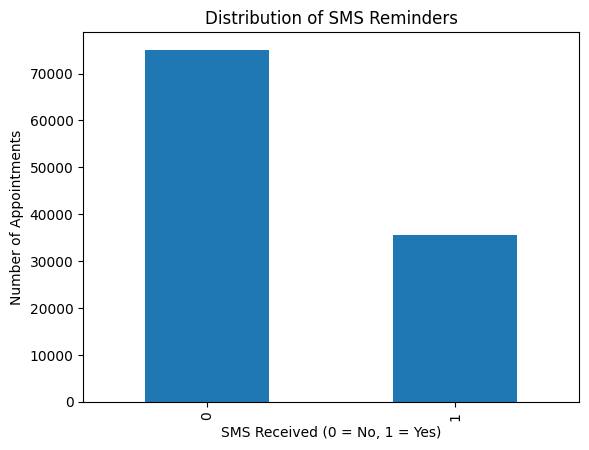

In [12]:
distribution("SMS_received").plot(kind="bar")
plt.xlabel("SMS Received (0 = No, 1 = Yes)")
plt.ylabel("Number of Appointments")
plt.title("Distribution of SMS Reminders")
plt.show()

>This univariate analysis looks at the natural distribution of SMS reminders in the dataset. Since were only examining one variable on its own, this reflects common cause variation. The chart shows that most appointments didn't include an SMS reminder, with a much smaller portion receiving one.

### How do SMS reminders and patient age relate to apointment no-show rates?

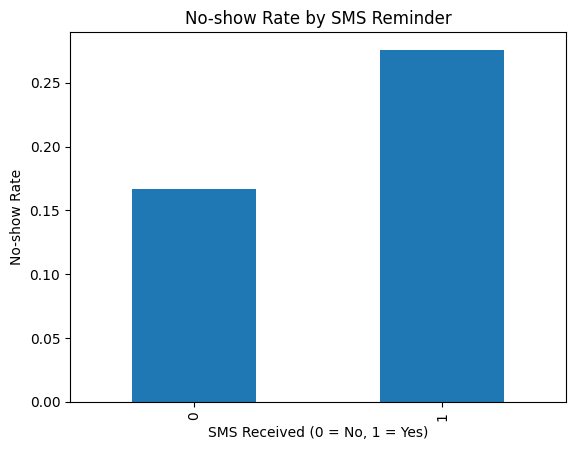

In [15]:
no_show_rate("SMS_received").plot(kind="bar")
plt.xlabel("SMS Received (0 = No, 1 = Yes)")
plt.ylabel("No-show Rate")
plt.title("No-show Rate by SMS Reminder")
plt.show()

>This bivariate analysis compares no-show rates between patients who received SMS reminder and those who did not. Patients without an SMS reminder missed their appointments about 17% of the time, while those who did get a reminder text had a higher no-show rate of around 28%. In this dataset, receiving an SMS reminder wasn't linked to lower no-show rates.

### How do age and SMS reminders together affect no-show rates?

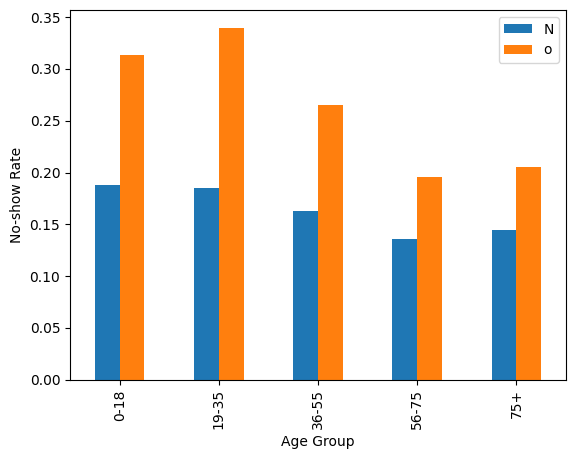

In [16]:
df.groupby(
    ["Age_group",
    "SMS_received"]
)["No-show"].mean().unstack().plot(kind="bar")

plt.xlabel("Age Group")
plt.ylabel("No-show Rate")
plt.legend("No-show Rate by Age Group and SMS Reminder")
plt.show()

>This multivariate analysis looks at how age and SMS reminders work together in relation to no-show rates. Since we're examining more than one factor at the same time, this helps show whether the effect of SMS reminders changes across different age groups. Younger patients have higher no-show rates regardless of whether they received an SMS reminder or not, and older patients tend to show up more reliably. This suggests age may play a stronger role in attendance behaviours than reminders alone.

<a id='conclusions'></a>
## Conclusions

>This report explored three questions to better understand patterns in medical appointment attendance. First, the univariate analysis showed the natural distribution of SMS reminders in the dataset. Most appointments did not include an SMS reminder.
>
>The bivariate analysis examined whether receiving an SMS reminder was associated with different no-show rates. Interestingly, patients who received an SMS reminder had a higher no-show rate than those who did not. This doesn't mean the reminders caused more missed appointments, but it shows how the two varibles behaved in this dataset.
>
>The multivariate analysis combined age groups with SMS reminder status to see how these factors worked together. Younger patients consistently had higher no-show rates regardless of whether they received a reminder, while older patients attended more reliably. This suggests that age may play a stronger role in attendace than SMS reminders alone.
>
>One limitation to keep in mind is that this dataset is observational, so it can show relationships but cannot establish causation. It also lacks context such as transportation issues, work schedules, and home life situations. This limits how fully we can explain why patients missed their appointments.

In [ ]:
# Running this cell will execute a bash command to convert this notebook to an .html file
!python -m nbconvert --to html Investigate_a_Dataset.ipynb